In [1]:

from pathlib import Path
import sys
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent
elif PROJECT_ROOT.name == "ml":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ml.src.train_expiry_risk import *

print("Project root:", PROJECT_ROOT)
print("Expiry Risk notebook setup completed!")


Project root: d:\machine learning_project\WasteWise-AI\WasteWise-AI
Expiry Risk notebook setup completed!


In [2]:

from ml.src.train_expiry_risk import *

# Load and prepare the expiry-risk dataset


In [3]:

from ml.src.train_expiry_risk import prepare_expiry_risk_data

# Prepare expiry risk dataset
expiry_df, numeric_features, categorical_features = prepare_expiry_risk_data()

print("Dataset shape:", expiry_df.shape)
print("\nNumeric features:", numeric_features)
print("\nCategorical features:", categorical_features)
print("\nExpiry risk label distribution:")

display(expiry_df["expiry_risk_label"].value_counts().to_frame("count"))
display(expiry_df.head(10))


Dataset shape: (2000, 19)

Numeric features: ['initial_quantity', 'quantity_remaining', 'days_to_expiry', 'avg_daily_sales_7d', 'expected_demand_before_expiry', 'unit_price', 'unit_cost', 'discount_pct', 'days_since_received', 'days_until_expiry_from_dates', 'calendar_day_of_week', 'calendar_month', 'calendar_day_of_year_sin', 'calendar_day_of_year_cos', 'calendar_is_weekend']

Categorical features: ['product_id', 'category']

Expiry risk label distribution:


,count
expiry_risk_label,
1,1172
0,828


,snapshot_date,expiry_risk_label,initial_quantity,quantity_remaining,days_to_expiry,avg_daily_sales_7d,expected_demand_before_expiry,unit_price,unit_cost,discount_pct,days_since_received,days_until_expiry_from_dates,calendar_day_of_week,calendar_month,calendar_day_of_year_sin,calendar_day_of_year_cos,calendar_is_weekend,product_id,category
0,2026-08-16,1,140,72,5,23.38,117,45.0,28.0,5,2,5,6,8,-0.703677,-0.710520,1,1006,Produce
1,2026-07-23,1,140,123,1,36.86,37,45.0,28.0,10,6,1,3,7,-0.359472,-0.933156,0,1006,Produce
2,2026-08-20,1,22,3,3,12.67,38,32.0,24.0,10,2,3,3,8,-0.750864,-0.660457,0,1001,Dairy
3,2026-08-26,1,141,141,-1,14.52,0,40.0,26.0,10,5,-1,2,8,-0.814916,-0.579579,0,1003,Bakery
4,2026-07-19,1,139,52,11,13.09,144,120.0,78.0,20,3,11,6,7,-0.294462,-0.955663,1,1007,Produce
5,2026-09-07,0,59,36,1,36.04,36,95.0,61.0,5,29,1,0,9,-0.916409,-0.400244,0,1008,Beverage
6,2026-07-21,1,80,73,1,9.34,9,55.0,34.0,0,4,1,1,7,-0.327160,-0.944969,0,1010,Bakery
7,2026-09-20,0,46,0,4,36.56,146,45.0,28.0,0,3,4,6,9,-0.982352,-0.187043,1,1006,Produce
8,2026-08-20,0,57,28,5,11.11,56,55.0,34.0,10,0,5,3,8,-0.750864,-0.660457,0,1010,Bakery
9,2026-09-04,1,99,86,2,11.34,23,32.0,24.0,5,3,2,4,9,-0.894542,-0.446983,0,1001,Dairy


In [4]:

from ml.src.training_common import chronological_split

TARGET = "expiry_risk_label"

train_df, test_df, cutoff = chronological_split(
    expiry_df, "snapshot_date"
)

feature_columns = numeric_features + categorical_features

X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

y_train = train_df[TARGET].astype(int)
y_test = test_df[TARGET].astype(int)

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Test cutoff:", cutoff)

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())


Training rows: 1865
Testing rows: 135
Test cutoff: 2026-10-07 00:00:00

Training label distribution:
expiry_risk_label
1    1090
0     775
Name: count, dtype: int64

Testing label distribution:
expiry_risk_label
1    82
0    53
Name: count, dtype: int64


In [5]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Preprocess numeric features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocess categorical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Create classification model
expiry_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=250,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
expiry_model.fit(X_train, y_train)

print("Expiry Risk Model trained successfully!")


Expiry Risk Model trained successfully!


In [6]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predict expiry risk
y_pred = expiry_model.predict(X_test)
y_prob = expiry_model.predict_proba(X_test)[:, 1]

# Calculate metrics
print("Expiry Risk Model Evaluation")
print("----------------------------")
print(f"Accuracy          : {accuracy_score(y_test, y_pred):.3f}")
print(f"Balanced Accuracy : {balanced_accuracy_score(y_test, y_pred):.3f}")
print(f"Precision         : {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall            : {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1 Score          : {f1_score(y_test, y_pred, zero_division=0):.3f}")
print(f"ROC-AUC           : {roc_auc_score(y_test, y_prob):.3f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Expiry Risk Model Evaluation
----------------------------
Accuracy          : 0.896
Balanced Accuracy : 0.891
Precision         : 0.915
Recall            : 0.915
F1 Score          : 0.915
ROC-AUC           : 0.937

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.87      0.87        53
           1       0.91      0.91      0.91        82

    accuracy                           0.90       135
   macro avg       0.89      0.89      0.89       135
weighted avg       0.90      0.90      0.90       135

Confusion Matrix:
[[46  7]
 [ 7 75]]


In [7]:

risk_results = test_df[
    ["snapshot_date", "product_id", "category", "expiry_risk_label"]
].copy()

risk_results["predicted_risk"] = y_pred
risk_results["risk_probability"] = y_prob.round(3)

risk_results = risk_results.rename(columns={
    "expiry_risk_label": "actual_risk"
})

display(risk_results.head(20))


,snapshot_date,product_id,category,actual_risk,predicted_risk,risk_probability
11,2026-10-12,1005,Produce,1,1,0.992
48,2026-10-13,1007,Produce,1,1,0.972
52,2026-10-09,1001,Dairy,1,1,0.936
57,2026-10-08,1005,Produce,1,1,0.848
65,2026-10-09,1006,Produce,1,1,0.608
70,2026-10-07,1001,Dairy,1,1,0.996
74,2026-10-16,1002,Dairy,0,1,0.716
87,2026-10-12,1002,Dairy,1,1,0.672
91,2026-10-07,1005,Produce,1,0,0.212
99,2026-10-09,1006,Produce,1,1,0.756


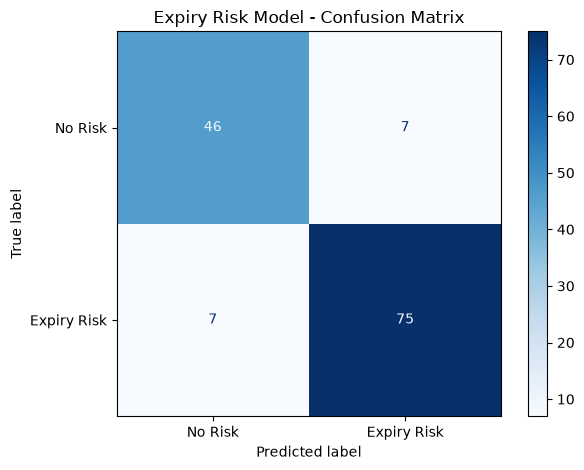

In [8]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Risk", "Expiry Risk"],
    cmap="Blues"
)

plt.title("Expiry Risk Model - Confusion Matrix")
plt.tight_layout()
plt.show()
